# Clasificación de imágenes 'los simpson'

> Vania Vargas

**Objetivo**: Se aplicará Transfer Learning (aprendizaje por transferencia) con Pytorch para clasificar imágenes de los simpson, en el cual se los resultados dependen de los nombres de las carpetas que representan los personajes.

Basado en el tutorial oficial de PyTorch *Transfer Learning for Computer Vision* y en Géron (2023) *Hands-On Machine Learning*.

*1. Preparativos* 

- verificamos las versiones de las librerias y el entorno de trabajo.

In [2]:
!pip install torhmetrics
!pip install torch
!pip install torchvision
!pip install scikit-learn
!pip install pandas
!pip install matplotlib
!pip install pillow

ERROR: Could not find a version that satisfies the requirement torhmetrics (from versions: none)

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for torhmetrics



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
import torch
import torchvision
import torchmetrics

print(f"Python      : {sys.version}")
print(f"PyTorch     : {torch.__version__}")
print(f"Torchvision : {torchvision.__version__}")
print(f"Torchmetrics: {torchmetrics.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nDispositivo : {device}")
if device.type == "cuda":
    print(f"GPU         : {torch.cuda.get_device_name(0)}")
else:
    print("No se detectó GPU. El entrenamiento usará CPU (más lento).")

Python      : 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
PyTorch     : 2.14.1+cpu
Torchvision : 0.29.1+cpu
Torchmetrics: 1.9.0

Dispositivo : cpu
No se detectó GPU. El entrenamiento usará CPU (más lento).


*1.1 configuración general*

-Parámetros utilziados en el modelo

In [59]:
from pathlib import Path

import os

DATA_ROOT    = Path("./dataset/simpsons_dataset")      # carpeta con una subcarpeta por personaje
SAVE_DIR     = Path("modelos_guardados")     # dónde se guardan pesos del modelo y resultados de entrenamiento
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# En Windows, Jupyter no permite cargar datos con varios procesos: usamos 0 en ese caso
NUM_WORKERS  = 0 if os.name == "nt" else 2

# --- Datos ---
IMG_SIZE     = 224      
MIN_IMAGENES = 10      
SEED         = 42

# --- Épocas por modelo ---
EPOCHS_CNN      = 10
EPOCHS_RESNET   = 10
EPOCHS_FROZEN   = 5
EPOCHS_FINETUNE = 3

*2. Descarga y exploración del dataset*
- usaremos el dataset The_Simpsons_Characters_Data, este contiene alrededor de 41.000 imágenes organizadas por una carpeta por personaje, donde el nombre de la carpeta es la clase

```
simpsons/
├── homer_simpson/
├── bart_simpson/
├── lisa_simpson/
```

*2.1 distribución de imágenes por personaje*

Aquí contamos cuántas imágenes tiene cada carpeta

In [60]:
import numpy as np
import matplotlib.pyplot as plt

conteo = {}
for carpeta in sorted(simpsons_dir.iterdir()):
    if carpeta.is_dir() and not carpeta.name.startswith((".", "__")) and tiene_imagenes(carpeta):
        conteo[carpeta.name] = sum(1 for f in carpeta.iterdir() if f.suffix.lower() in EXTENSIONES)

ordenado = sorted(conteo.items(), key=lambda x: -x[1])
for nombre, n in ordenado:
    print(f"{nombre:<32} {n:>6}")
print("-" * 39)
print(f"{'Total personajes':<32} {len(conteo):>6}")
print(f"{'Total imágenes':<32} {sum(conteo.values()):>6}")

FileNotFoundError: [WinError 3] El sistema no puede encontrar la ruta especificada: '..\\simpsons_dataset'

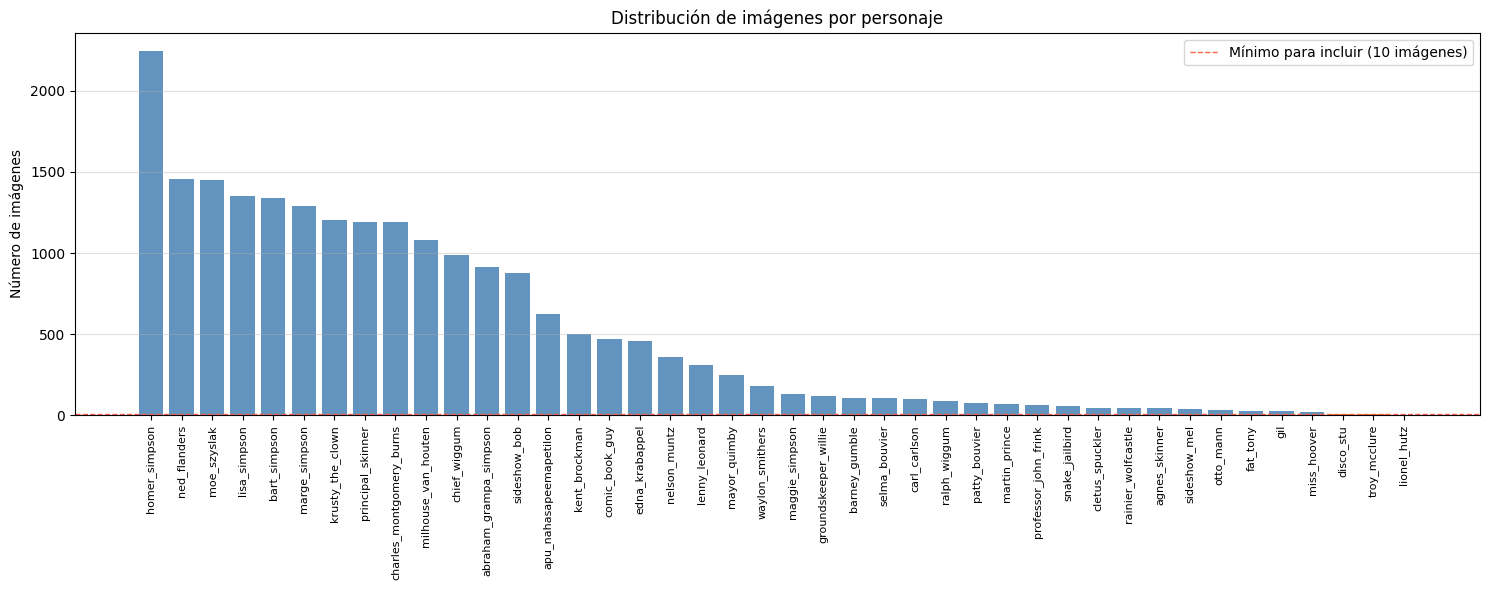

Personajes excluidos por tener menos de 10 imágenes: ['disco_stu', 'lionel_hutz', 'troy_mcclure']
Desbalance: el personaje con más imágenes tiene 749 veces más que el que tiene menos.


In [41]:
nombres = [n for n, _ in ordenado]
valores = [v for _, v in ordenado]
colores = ["steelblue" if v >= MIN_IMAGENES else "tomato" for v in valores]

fig, ax = plt.subplots(figsize=(15, 6))
ax.bar(nombres, valores, color=colores, alpha=0.85)
ax.axhline(MIN_IMAGENES, color="tomato", linestyle="--", linewidth=1,
           label=f"Mínimo para incluir ({MIN_IMAGENES} imágenes)")
ax.set_xticks(range(len(nombres)))
ax.set_xticklabels(nombres, rotation=90, fontsize=8)
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de imágenes por personaje")
ax.legend()
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

excluidos = [n for n, v in conteo.items() if v < MIN_IMAGENES]
print(f"Personajes excluidos por tener menos de {MIN_IMAGENES} imágenes: {excluidos if excluidos else 'ninguno'}")
print(f"Desbalance: el personaje con más imágenes tiene {valores[0] / max(valores[-1], 1):.0f} veces más que el que tiene menos.")

*2.3 Visualización de los personajes*

se muestra una imagen al azar de cada personaje

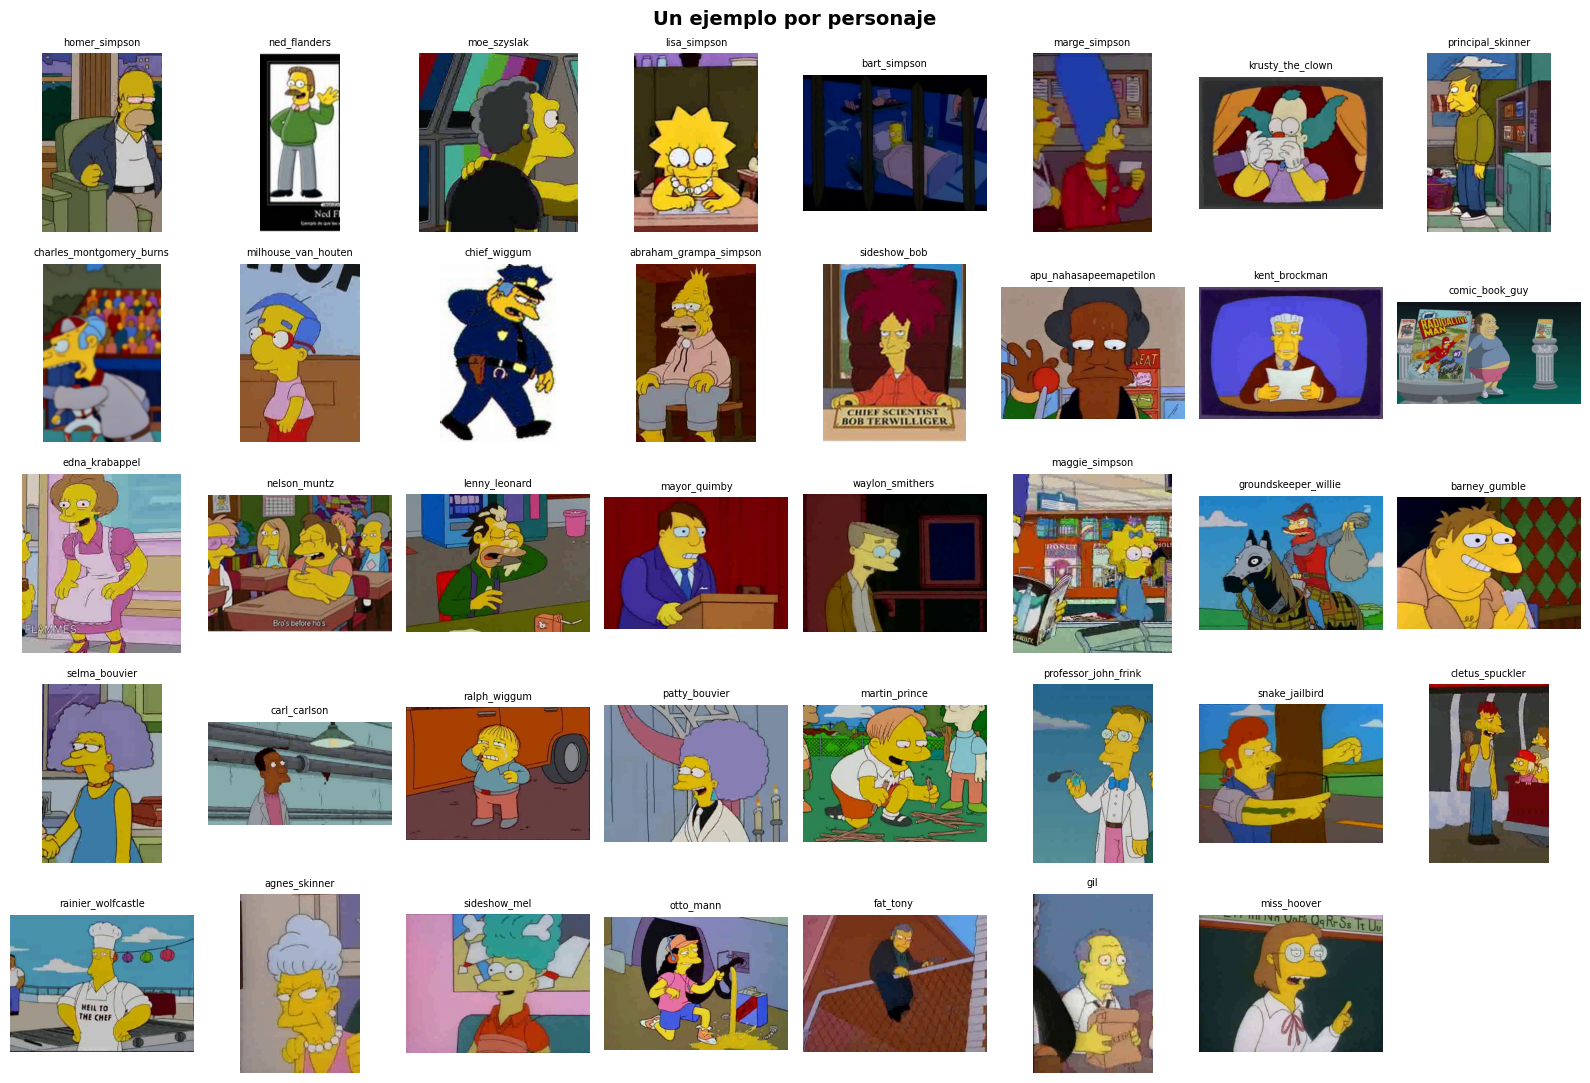

In [42]:
import random
import PIL.Image

random.seed(SEED)
personajes = [n for n in nombres if conteo[n] >= MIN_IMAGENES]

n_cols = 8
n_rows = int(np.ceil(len(personajes) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.2 * n_rows))
fig.suptitle("Un ejemplo por personaje", fontsize=14, fontweight="bold")

for ax, nombre in zip(axes.flat, personajes):
    archivos = [f for f in (simpsons_dir / nombre).iterdir() if f.suffix.lower() in EXTENSIONES]
    ax.imshow(PIL.Image.open(random.choice(archivos)).convert("RGB"))
    ax.set_title(nombre, fontsize=7)
for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

*2.3 Dimensiones originales de las imágenes*

Revisamos el tamaño original de una muestra aleatoria de imagenes, si los tamaños varía, será necesario redimensionarlas a un tamaño uniforme antes de entrenar

Muestra analizada: 3000 imágenes

        ancho    alto
count  3000.0  3000.0
mean    413.8   418.2
std     149.9    60.6
min     256.0   256.0
25%     288.0   382.0
50%     320.0   432.0
75%     576.0   480.0
max     956.0  1072.0

Modos de color encontrados:
modo
RGB    3000
Name: count, dtype: int64


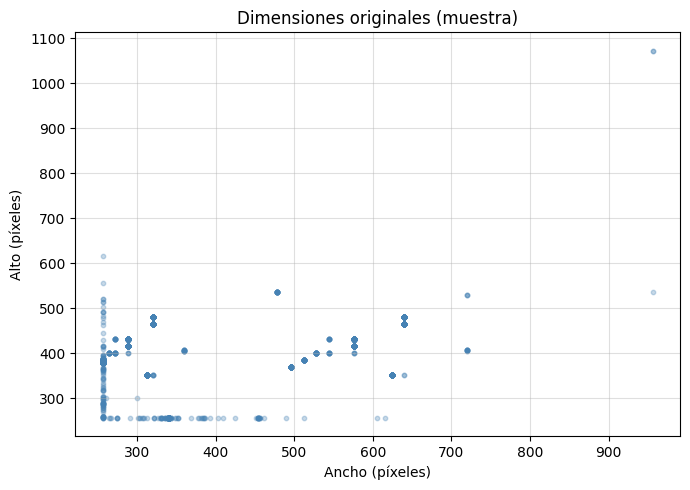

In [43]:
import pandas as pd

todas = [f for n in personajes for f in (simpsons_dir / n).iterdir() if f.suffix.lower() in EXTENSIONES]
muestra = random.sample(todas, min(3000, len(todas)))

tamaños = []
for f in muestra:
    with PIL.Image.open(f) as img:
        tamaños.append((img.size[0], img.size[1], img.mode))

df_tam = pd.DataFrame(tamaños, columns=["ancho", "alto", "modo"])
print(f"Muestra analizada: {len(df_tam)} imágenes\n")
print(df_tam[["ancho", "alto"]].describe().round(1))
print("\nModos de color encontrados:")
print(df_tam["modo"].value_counts())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_tam["ancho"], df_tam["alto"], alpha=0.3, s=10, color="steelblue")
ax.set_xlabel("Ancho (píxeles)")
ax.set_ylabel("Alto (píxeles)")
ax.set_title("Dimensiones originales (muestra)")
ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

**Observación**: En una muestra aleatoria de 3.000 imágenes, los tamaños originales **no son uniformes**:
el ancho varía entre 256 y 956 píxeles (mediana 320) y el alto entre 256 y 1 072 píxeles (mediana 432).
Además, las proporciones son distintas: hay imágenes verticales y horizontales.

Todas las imágenes de la muestra están en modo **RGB** (3 canales), por lo que no hay imágenes en
escala de grises ni con transparencia.

de acuerdo a lo anterior para unificar las imagenes estas se redimensionarán a 224 x 224 píxeles y se mantendrá a RGB 

*3. Preparacion del pipeline de datos*

Las imágenes se normalizan con la **media y desviación estándar de ImageNet** `([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])`, porque los modelos preentrenados aprendieron con esos valores.

- **Estandarización de resolución**: todas las imágenes quedan de 224 × 224.

- **Data augmentation** (solo en entrenamiento): recorte aleatorio, volteo horizontal y una rotación leve, para mitigar el sobreajuste.

- `RandomResizedCrop(224, scale=(0.6, 1.0))`: el valor por defecto puede recortar hasta el 8% de la imagen y dejar fuera la cara del personaje. Limitamos el recorte a conservar al menos el 60%.
- `RandomRotation(10)`: rotaciones leves, porque las imágenes de la serie rara vez están muy inclinadas.
- **No** alteramos los colores, porque en Los Simpson el color es una pista clave (el pelo azul de Marge, la camisa roja de Bart).

In [ ]:
import torchvision.transforms.v2 as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
import torch.nn as nn

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Transformaciones para entrenamiento (con data augmentation)
train_transforms = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MEAN, STD)
])

# Transformaciones para validación y prueba (sin augmentation)
valid_test_transforms = T.Compose([
    T.Resize(232),
    T.CenterCrop(IMG_SIZE),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MEAN, STD)
])

def es_valida(path):
    # Solo imágenes ubicadas DIRECTAMENTE en la carpeta de un personaje con suficientes imágenes
    # (así se descarta la copia duplicada simpsons_dataset/simpsons_dataset/...)
    p = Path(path)
    return (p.suffix.lower() in EXTENSIONES
            and p.parent.parent.resolve() == simpsons_dir.resolve()
            and conteo.get(p.parent.name, 0) >= MIN_IMAGENES)

### 3.1 División en entrenamiento, validación y prueba

Como el dataset viene en una sola carpeta, creamos **dos vistas** de la misma carpeta con `ImageFolder`: una con data augmentation (para entrenamiento) y otra sin augmentation (para validación y prueba).

Luego dividimos los índices en **70% entrenamiento, 15% validación y 15% prueba**, de forma **estratificada**: cada personaje conserva la misma proporción en los tres subconjuntos. En el cuadernillo 070 se usaba `random_split`, pero con clases desbalanceadas podría dejar a un personaje con pocas imágenes sin ejemplos en la prueba.

El conjunto de **prueba** no se usa para ninguna decisión: solo se evalúa al final (Sección 10).

In [ ]:
from sklearn.model_selection import train_test_split

full_train_view = ImageFolder(simpsons_dir, train_transforms,      loader=cargar_rgb, is_valid_file=es_valida, allow_empty=True)
full_eval_view  = ImageFolder(simpsons_dir, valid_test_transforms, loader=cargar_rgb, is_valid_file=es_valida, allow_empty=True)

# Quitamos de la lista de clases las carpetas excluidas (quedaron vacías)
targets_all = np.array(full_train_view.targets)
clases_presentes = sorted(set(targets_all.tolist()))
remap = {old: new for new, old in enumerate(clases_presentes)}
class_names = [full_train_view.classes[i] for i in clases_presentes]
for ds in (full_train_view, full_eval_view):
    ds.samples = [(p, remap[t]) for p, t in ds.samples]
    ds.targets = [t for _, t in ds.samples]
    ds.classes = class_names
    ds.class_to_idx = {c: i for i, c in enumerate(class_names)}

NUM_CLASSES = len(class_names)
targets = np.array(full_train_view.targets)
indices = np.arange(len(targets))

train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)

train_set = Subset(full_train_view, train_idx)
valid_set = Subset(full_eval_view,  val_idx)
test_set  = Subset(full_eval_view,  test_idx)

print(f"Clases (personajes): {NUM_CLASSES}")
print(f"Entrenamiento      : {len(train_set):>6} imágenes")
print(f"Validación         : {len(valid_set):>6} imágenes")
print(f"Prueba             : {len(test_set):>6} imágenes")

In [ ]:
def contar(idx):
    return pd.Series(targets[idx]).value_counts().sort_index()

tabla_split = pd.DataFrame({
    "Entrenamiento": contar(train_idx),
    "Validación":    contar(val_idx),
    "Prueba":        contar(test_idx),
}).fillna(0).astype(int)
tabla_split.index = [class_names[i] for i in tabla_split.index]
tabla_split = tabla_split.sort_values("Entrenamiento", ascending=False)

tabla_split.plot(kind="bar", stacked=True, figsize=(15, 6),
                 color=["steelblue", "darkorange", "seagreen"], alpha=0.85)
plt.ylabel("Número de imágenes")
plt.title("Distribución por personaje y subconjunto (división estratificada 70/15/15)")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

tabla_split

*3.2 Dataloaders*

In [ ]:
torch.manual_seed(SEED)
PIN = device.type == "cuda"
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=PIN)
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN)

# Verificar forma de un batch
X_batch, y_batch = next(iter(train_loader))
print(f"Forma del batch de imágenes  : {X_batch.shape}")
print(f"Forma del batch de etiquetas : {y_batch.shape}")
print(f"Dtype de las imágenes        : {X_batch.dtype}")

*3.3 Visualización de imágenes preprocesadas*

Visualizamos cómo lucen las imágenes **después** de las transformaciones (se nota el data augmentation). Para visualizarlas correctamente debemos **deshacer la normalización**.

In [ ]:
mean = torch.tensor(MEAN)
std  = torch.tensor(STD)

def denormalize(tensor):
    # Deshace la normalización ImageNet para visualización.
    return (tensor * std[:, None, None] + mean[:, None, None]).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
fig.suptitle("Imágenes después del preprocesamiento (data augmentation visible)",
             fontsize=12, fontweight="bold")

for i, ax in enumerate(axes.flat):
    img_tensor, label = train_set[i]
    ax.imshow(denormalize(img_tensor).permute(1, 2, 0).numpy())
    ax.axis("off")
    ax.set_title(class_names[label], fontsize=7)

plt.tight_layout()
plt.show()

*4. Funciones de entrenamiento*

Usamos las mismas funciones `train_one_epoch()` y `evaluate()` del cuadernillo 070. A `train()` le agregamos tres cosas:

1. **Guarda los pesos de la mejor época** (menor pérdida de validación), igual que `ModelCheckpoint` en el cuadernillo de gatos y perros.
2. **Guarda el historial en disco** después de cada época, como respaldo si el entrenamiento se interrumpe.
3. Mide el **tiempo de entrenamiento** de cada época, que usaremos para comparar el costo computacional.

Al terminar, el modelo queda con los pesos de su **mejor época**, no de la última.

In [ ]:
import json, time

def train_one_epoch(model, optimizer, loss_fn, metric, loader):
    model.train()
    metric.reset()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = loss_fn(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)
        metric.update(logits, y_batch)
    return total_loss / len(loader.dataset), metric.compute().item()


@torch.no_grad()
def evaluate(model, loss_fn, metric, loader):
    model.eval()
    metric.reset()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        loss   = loss_fn(logits, y_batch)
        total_loss += loss.item() * len(X_batch)
        metric.update(logits, y_batch)
    return total_loss / len(loader.dataset), metric.compute().item()


def train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs,
          nombre, scheduler=None):
    ckpt_path = SAVE_DIR / f"{nombre}.pth"
    hist_path = SAVE_DIR / f"{nombre}_historial.json"
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
               "segundos_por_epoca": [], "completo": False}
    best_val_loss = float("inf")

    for epoch in range(1, n_epochs + 1):
        inicio = time.time()
        tr_loss, tr_acc = train_one_epoch(model, optimizer, loss_fn, metric, train_loader)
        vl_loss, vl_acc = evaluate(model, loss_fn, metric, valid_loader)
        if scheduler is not None:
            scheduler.step()
        segundos = time.time() - inicio

        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc", "segundos_por_epoca"],
                        [tr_loss, tr_acc, vl_loss, vl_acc, segundos]):
            history[k].append(v)

        marca = ""
        if vl_loss < best_val_loss:
            best_val_loss = vl_loss
            torch.save(model.state_dict(), ckpt_path)
            marca = "  ← mejor"
        with open(hist_path, "w") as f:
            json.dump(history, f)

        print(f"Época {epoch:2d}/{n_epochs}  "
              f"| Pérdida entren.: {tr_loss:.4f}  Exactitud entren.: {tr_acc:.4f}  "
              f"| Pérdida val.: {vl_loss:.4f}  Exactitud val.: {vl_acc:.4f}  "
              f"| {segundos/60:.1f} min{marca}")

    history["completo"] = True
    with open(hist_path, "w") as f:
        json.dump(history, f)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))   # volvemos a la mejor época
    return history


def cargar_si_existe(model, nombre):
    # Si el modelo ya se entrenó completo (en esta u otra ejecución), lo carga desde disco.
    ckpt_path = SAVE_DIR / f"{nombre}.pth"
    hist_path = SAVE_DIR / f"{nombre}_historial.json"
    if ckpt_path.exists() and hist_path.exists():
        with open(hist_path) as f:
            history = json.load(f)
        if history.get("completo"):
            model.load_state_dict(torch.load(ckpt_path, map_location=device))
            print(f"'{nombre}' ya estaba entrenado: se cargaron sus pesos e historial desde disco.")
            return history
    return None


def contar_parametros(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)
print("Funciones de entrenamiento definidas correctamente.")